# BBC News Category Classification

# 1. Problem Understanding

## 1.1 Problem Statement

News articles are published every day across different domains.
Manually categorizing a large number of news articles is
time-consuming and inefficient.

The objective of this project is to develop a Natural Language
Processing (NLP) model that automatically classifies news
articles into their respective categories based on their text.

## 1.2 Project Objectives

- Understand and analyze the BBC News dataset.
- Perform data cleaning and exploratory data analysis.
- Apply NLP text preprocessing techniques.
- Convert text into numerical features.
- Build and train machine learning classification models.
- Evaluate model performance using appropriate metrics.
- Predict categories for new and unseen news articles.

## 1.3 Project Scope

The model will classify news articles into five categories:

1. Business
2. Entertainment
3. Politics
4. Sport
5. Tech

## 1.4 Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- NLTK
- Scikit-learn
- TF-IDF
- Multinomial Naive Bayes

## 1.5 Expected Outcome

Develop a machine learning model that can automatically
identify the category of a news article based on its content.

# 2. Dataset Collection and Loading

The BBC News dataset contains news articles along with their
corresponding category labels.

The dataset has already been downloaded and is available
locally as a CSV file.

We will load the dataset using Pandas and inspect its structure.
Latin-1 encoding is used to handle special characters in the file.

## 2.1 Import Required Library

In [94]:
import pandas as pd
import numpy as np

## 2.2 Load Dataset

In [95]:
news_data = pd.read_csv(
    "bbc_news.csv",
    encoding="latin-1"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2.3 Display First Five Records

In [96]:
news_data.head()

,news,type
0,China had role in Yukos split-up\r\n \r\n Chin...,business
1,Oil rebounds from weather effect\r\n \r\n Oil ...,business
2,Indonesia 'declines debt freeze'\r\n \r\n Indo...,business
3,$1m payoff for former Shell boss\r\n \r\n Shel...,business
4,US bank in $515m SEC settlement\r\n \r\n Five ...,business


## 2.4 Check Dataset Dimensions

In [97]:
print("Number of Rows:", news_data.shape[0])
print("Number of Columns:", news_data.shape[1])

Number of Rows: 2225
Number of Columns: 2


## 2.5 Check Column Names

In [98]:
print("Dataset Columns:")
print(news_data.columns.tolist())

Dataset Columns:
['news', 'type']


# 3. Data Understanding

Data understanding helps us identify the structure,
characteristics, and contents of the dataset.

We will examine the dataset information, data types,
statistical summary, and sample records.

## 3.1 Dataset Information

In [99]:
news_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   news    2225 non-null   object
 1   type    2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB


## 3.2 Check Data Types

In [100]:
print(news_data.dtypes)

news    object
type    object
dtype: object


## 3.3 Statistical Summary

In [101]:
news_data.describe(include="all")

,news,type
count,2225,2225
unique,2127,5
top,Brits return Keane to number one\r\n \r\n Brit...,sport
freq,2,511


## 3.4 Display Random Sample Records

In [102]:
news_data.sample(5, random_state=42)

,news,type
414,Fresh hope after Argentine crisis\r\n \r\n Thr...,business
420,Dollar drops on reserves concerns\r\n \r\n The...,business
1644,Lomu relishing return to action\r\n \r\n Forme...,sport
416,Weak dollar trims Cadbury profits\r\n \r\n The...,business
1232,Top judge clashes with ministers\r\n \r\n The ...,politics


# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns,
distributions, and quality of the dataset.

We will analyze missing values, duplicate records,
category distribution, and article length.

## 4.1 Import Visualization Libraries

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

## 4.2 Check Missing Values

In [104]:
print("Missing Values:")
display(news_data.isnull().sum())

Missing Values:


news    0
type    0
dtype: int64

## 4.3 Check Duplicate Records

In [105]:
print("Total Duplicate Records:", news_data.duplicated().sum())

Total Duplicate Records: 98


## 4.4 Check Category Distribution

In [106]:
# The original dataset uses the column 'type'

if "type" in news_data.columns:
    category_column = "type"
elif "category" in news_data.columns:
    category_column = "category"
else:
    raise ValueError("Category column not found.")

news_data[category_column].value_counts()

type
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

## 4.5 Visualize Category Distribution

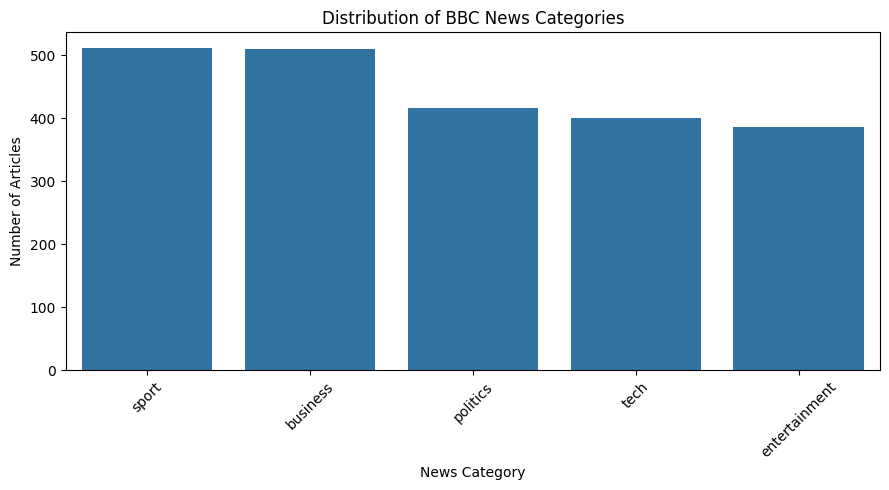

In [107]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=news_data,
    x=category_column,
    order=news_data[category_column].value_counts().index
)

plt.title("Distribution of BBC News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4.6 Analyze Article Length

In [108]:
# Identify the original article text column

if "news" in news_data.columns:
    text_column = "news"
elif "text" in news_data.columns:
    text_column = "text"
else:
    raise ValueError("Article text column not found.")

news_data["word_count"] = (
    news_data[text_column]
    .fillna("")
    .astype(str)
    .apply(lambda text: len(text.split()))
)

news_data[["word_count"]].head()

,word_count
0,443
1,233
2,349
3,236
4,386


## 4.7 Visualize Word Count Distribution

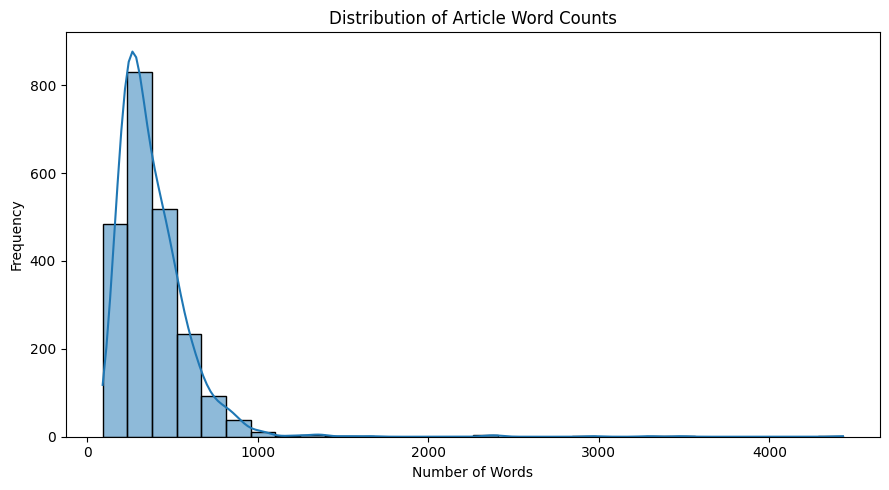

In [109]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=news_data,
    x="word_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Article Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 4.8 Average Article Length by Category

In [110]:
average_words = news_data.groupby(
    category_column
)["word_count"].mean().sort_values(ascending=False)

display(average_words)

type
tech             502.695761
politics         453.973621
entertainment    330.621762
sport            329.262231
business         328.880392
Name: word_count, dtype: float64

## 4.9 Visualize Average Article Length

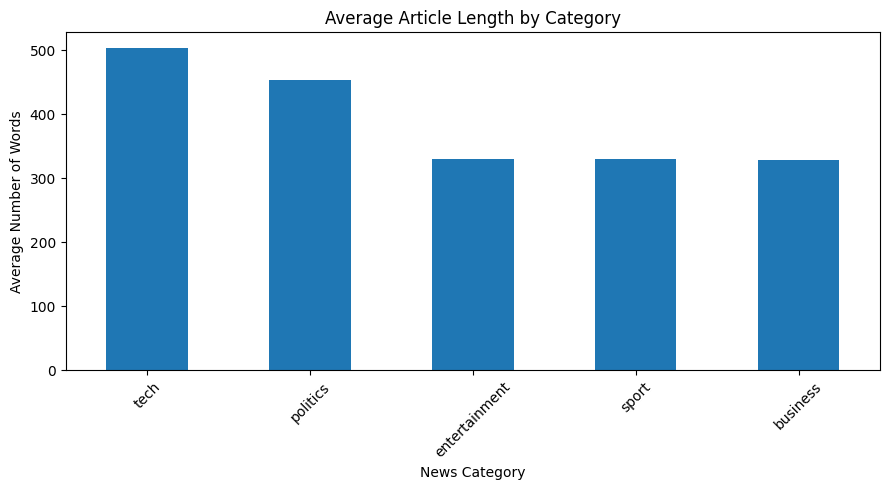

In [111]:
plt.figure(figsize=(9, 5))

average_words.plot(kind="bar")

plt.title("Average Article Length by Category")
plt.xlabel("News Category")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 4.10 EDA Observations

After completing the exploratory analysis, observe the following:

1. Identify the total number of news articles.
2. Identify the category containing the highest number of articles.
3. Identify the category containing the lowest number of articles.
4. Observe the distribution of article lengths.
5. Compare average article lengths across categories.
6. Identify missing and duplicate records.

These observations help us understand the dataset before
performing data cleaning and text preprocessing.

# 5. Data Cleaning

Data cleaning ensures that the dataset is consistent and
suitable for further NLP processing.

We will standardize column names, handle missing values,
remove empty articles, and remove duplicate records.

## 5.1 Standardize Column Names

In [112]:
news_data.columns = (
    news_data.columns.astype(str).str.strip().str.lower()
)

print(news_data.columns.tolist())

['news', 'type', 'word_count']


## 5.2 Rename Required Columns

In [113]:
rename_columns = {}

if "news" in news_data.columns and "text" not in news_data.columns:
    rename_columns["news"] = "text"

if "type" in news_data.columns and "category" not in news_data.columns:
    rename_columns["type"] = "category"

news_data = news_data.rename(columns=rename_columns)

print("Updated Columns:", news_data.columns.tolist())

Updated Columns: ['text', 'category', 'word_count']


## 5.3 Select Required Columns

In [114]:
required_columns = ["text", "category"]

if not all(column in news_data.columns for column in required_columns):
    raise ValueError(
        "Required columns not found: " +
        str(news_data.columns.tolist())
    )

news_data = news_data[required_columns].copy()

news_data.head()

,text,category
0,China had role in Yukos split-up\r\n \r\n Chin...,business
1,Oil rebounds from weather effect\r\n \r\n Oil ...,business
2,Indonesia 'declines debt freeze'\r\n \r\n Indo...,business
3,$1m payoff for former Shell boss\r\n \r\n Shel...,business
4,US bank in $515m SEC settlement\r\n \r\n Five ...,business


## 5.4 Handle Missing Values

In [115]:
print("Missing Values Before Cleaning:")
display(news_data.isnull().sum())

news_data = news_data.dropna(
    subset=["text", "category"]
)

print("Shape After Removing Missing Values:", news_data.shape)

Missing Values Before Cleaning:


text        0
category    0
dtype: int64

Shape After Removing Missing Values: (2225, 2)


## 5.5 Remove Empty Articles

In [116]:
news_data["text"] = news_data["text"].astype(str).str.strip()

news_data["category"] = (
    news_data["category"].astype(str).str.strip().str.lower()
)

news_data = news_data[
    (news_data["text"] != "") &
    (news_data["category"] != "")
]

print("Shape After Removing Empty Records:", news_data.shape)

Shape After Removing Empty Records: (2225, 2)


## 5.6 Remove Duplicate Records

In [117]:
print("Duplicates Before Cleaning:", news_data.duplicated().sum())

news_data = news_data.drop_duplicates(
    subset=["text", "category"]
).reset_index(drop=True)

print("Duplicates After Cleaning:", news_data.duplicated().sum())

Duplicates Before Cleaning: 98
Duplicates After Cleaning: 0


## 5.7 Verify Cleaned Dataset

In [118]:
print("Final Dataset Shape:", news_data.shape)

Final Dataset Shape: (2127, 2)


In [119]:
print("\nMissing Values:")
display(news_data.isnull().sum())


Missing Values:


text        0
category    0
dtype: int64

In [120]:
print("\nCategory Distribution:")
display(news_data["category"].value_counts())


Category Distribution:


category
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64

In [121]:
news_data.head()

,text,category
0,China had role in Yukos split-up\r\n \r\n Chin...,business
1,Oil rebounds from weather effect\r\n \r\n Oil ...,business
2,Indonesia 'declines debt freeze'\r\n \r\n Indo...,business
3,$1m payoff for former Shell boss\r\n \r\n Shel...,business
4,US bank in $515m SEC settlement\r\n \r\n Five ...,business


# 6. Text Preprocessing

Text preprocessing converts raw textual data into a cleaner
and more consistent format.

The following operations will be performed:

1. Convert text to lowercase.
2. Remove URLs.
3. Remove HTML tags.
4. Remove punctuation and special characters.
5. Remove numbers.
6. Remove extra whitespaces.

## 6.1 Import Regular Expressions

In [122]:
import re

## 6.2 Create Text Cleaning Function

In [123]:
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

## 6.3 Apply Text Cleaning

In [124]:
news_data["clean_text"] = news_data["text"].apply(clean_text)

news_data[["text", "clean_text"]].head()

,text,clean_text
0,China had role in Yukos split-up\r\n \r\n Chin...,china had role in yukos split up china lent ru...
1,Oil rebounds from weather effect\r\n \r\n Oil ...,oil rebounds from weather effect oil prices re...
2,Indonesia 'declines debt freeze'\r\n \r\n Indo...,indonesia declines debt freeze indonesia no lo...
3,$1m payoff for former Shell boss\r\n \r\n Shel...,m payoff for former shell boss shell is to pay...
4,US bank in $515m SEC settlement\r\n \r\n Five ...,us bank in m sec settlement five bank of ameri...


## 6.4 Compare Original and Cleaned Text

In [125]:
sample_index = 0

print("Original Article:\n")
print(news_data["text"].iloc[sample_index][:1000])

Original Article:

China had role in Yukos split-up
 
 China lent Russia $6bn (ÃÂ£3.2bn) to help the Russian government renationalise the key Yuganskneftegas unit of oil group Yukos, it has been revealed.
 
 The Kremlin said on Tuesday that the $6bn which Russian state bank VEB lent state-owned Rosneft to help buy Yugansk in turn came from Chinese banks. The revelation came as the Russian government said Rosneft had signed a long-term oil supply deal with China. The deal sees Rosneft receive $6bn in credits from China's CNPC.
 
 According to Russian newspaper Vedomosti, these credits would be used to pay off the loans Rosneft received to finance the purchase of Yugansk. Reports said CNPC had been offered 20% of Yugansk in return for providing finance but the company opted for a long-term oil supply deal instead. Analysts said one factor that might have influenced the Chinese decision was the possibility of litigation from Yukos, Yugansk's former owner, if CNPC had become a shareholder

In [126]:
print("\nCleaned Article:\n")
print(news_data["clean_text"].iloc[sample_index][:1000])


Cleaned Article:

china had role in yukos split up china lent russia bn bn to help the russian government renationalise the key yuganskneftegas unit of oil group yukos it has been revealed the kremlin said on tuesday that the bn which russian state bank veb lent state owned rosneft to help buy yugansk in turn came from chinese banks the revelation came as the russian government said rosneft had signed a long term oil supply deal with china the deal sees rosneft receive bn in credits from china s cnpc according to russian newspaper vedomosti these credits would be used to pay off the loans rosneft received to finance the purchase of yugansk reports said cnpc had been offered of yugansk in return for providing finance but the company opted for a long term oil supply deal instead analysts said one factor that might have influenced the chinese decision was the possibility of litigation from yukos yugansk s former owner if cnpc had become a shareholder rosneft and veb declined to comment t

## 6.5 Check Empty Text After Cleaning

In [127]:
print(
    "Empty articles after cleaning:",
    (news_data["clean_text"].str.len() == 0).sum()
)

news_data = news_data[
    news_data["clean_text"].str.len() > 0
].reset_index(drop=True)

Empty articles after cleaning: 0


# 7. Tokenization

Tokenization is the process of splitting text into smaller
units called tokens.

In this project, we will perform word-level tokenization.

## 7.1 Perform Word Tokenization

In [128]:
sample_text = news_data["clean_text"].iloc[0]

tokens = sample_text.split()

print("Original Cleaned Text:")
print(sample_text[:500])

Original Cleaned Text:
china had role in yukos split up china lent russia bn bn to help the russian government renationalise the key yuganskneftegas unit of oil group yukos it has been revealed the kremlin said on tuesday that the bn which russian state bank veb lent state owned rosneft to help buy yugansk in turn came from chinese banks the revelation came as the russian government said rosneft had signed a long term oil supply deal with china the deal sees rosneft receive bn in credits from china s cnpc according to


In [129]:
print("Tokenized Words:")
print(tokens[:50])

Tokenized Words:
['china', 'had', 'role', 'in', 'yukos', 'split', 'up', 'china', 'lent', 'russia', 'bn', 'bn', 'to', 'help', 'the', 'russian', 'government', 'renationalise', 'the', 'key', 'yuganskneftegas', 'unit', 'of', 'oil', 'group', 'yukos', 'it', 'has', 'been', 'revealed', 'the', 'kremlin', 'said', 'on', 'tuesday', 'that', 'the', 'bn', 'which', 'russian', 'state', 'bank', 'veb', 'lent', 'state', 'owned', 'rosneft', 'to', 'help', 'buy']


## 7.2 Apply Tokenization to All Articles

In [130]:
news_data["tokens"] = news_data["clean_text"].apply(
    lambda text: text.split()
)

news_data[["clean_text", "tokens"]].head()

,clean_text,tokens
0,china had role in yukos split up china lent ru...,"[china, had, role, in, yukos, split, up, china..."
1,oil rebounds from weather effect oil prices re...,"[oil, rebounds, from, weather, effect, oil, pr..."
2,indonesia declines debt freeze indonesia no lo...,"[indonesia, declines, debt, freeze, indonesia,..."
3,m payoff for former shell boss shell is to pay...,"[m, payoff, for, former, shell, boss, shell, i..."
4,us bank in m sec settlement five bank of ameri...,"[us, bank, in, m, sec, settlement, five, bank,..."


## 7.3 Analyze Token Counts

In [131]:
news_data["token_count"] = news_data["tokens"].apply(len)

news_data[["token_count"]].describe()

,token_count
count,2127.000000
mean,386.340386
std,243.606197
min,90.000000
25%,246.000000
50%,333.000000
75%,473.000000
max,4469.000000


# 8. Stopword Removal

Stopwords are commonly occurring words that may provide
limited information for a basic text-classification task.

Examples include:

- the
- is
- are
- and
- of
- in

We will remove English stopwords to focus on more informative
words.

## 8.1 Import English Stopwords

In [132]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

## 8.2 Identify Stopwords

In [133]:
print("Sample English Stopwords:")

print(list(ENGLISH_STOP_WORDS)[:30])

Sample English Stopwords:
['everything', 'per', 'thereupon', 'is', 'hence', 'part', 'latter', 'would', 'for', 'interest', 'again', 'amoungst', 'too', 'hereby', 'seems', 'all', 'on', 'beside', 'everyone', 'should', 'around', 'these', 'found', 'him', 'most', 'beforehand', 're', 'three', 'by', 'being']


## 8.3 Create Stopword Removal Function

In [134]:
def remove_stopwords(tokens):

    filtered_tokens = [
        word for word in tokens
        if word not in ENGLISH_STOP_WORDS
    ]

    return filtered_tokens

## 8.4 Apply Stopword Removal

In [135]:
news_data["filtered_tokens"] = news_data["tokens"].apply(
    remove_stopwords
)

news_data[["tokens", "filtered_tokens"]].head()

,tokens,filtered_tokens
0,"[china, had, role, in, yukos, split, up, china...","[china, role, yukos, split, china, lent, russi..."
1,"[oil, rebounds, from, weather, effect, oil, pr...","[oil, rebounds, weather, effect, oil, prices, ..."
2,"[indonesia, declines, debt, freeze, indonesia,...","[indonesia, declines, debt, freeze, indonesia,..."
3,"[m, payoff, for, former, shell, boss, shell, i...","[m, payoff, shell, boss, shell, pay, m, ex, fi..."
4,"[us, bank, in, m, sec, settlement, five, bank,...","[bank, m, sec, settlement, bank, america, subs..."


## 8.5 Compare Before and After Stopword Removal

In [136]:
print("Before Stopword Removal:")
print(news_data["tokens"].iloc[0][:30])

Before Stopword Removal:
['china', 'had', 'role', 'in', 'yukos', 'split', 'up', 'china', 'lent', 'russia', 'bn', 'bn', 'to', 'help', 'the', 'russian', 'government', 'renationalise', 'the', 'key', 'yuganskneftegas', 'unit', 'of', 'oil', 'group', 'yukos', 'it', 'has', 'been', 'revealed']


In [137]:
print("\nAfter Stopword Removal:")
print(news_data["filtered_tokens"].iloc[0][:30])


After Stopword Removal:
['china', 'role', 'yukos', 'split', 'china', 'lent', 'russia', 'bn', 'bn', 'help', 'russian', 'government', 'renationalise', 'key', 'yuganskneftegas', 'unit', 'oil', 'group', 'yukos', 'revealed', 'kremlin', 'said', 'tuesday', 'bn', 'russian', 'state', 'bank', 'veb', 'lent', 'state']


## 8.6 Convert Tokens Back to Text

In [138]:
news_data["processed_text"] = news_data["filtered_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

news_data[["clean_text", "processed_text"]].head()

,clean_text,processed_text
0,china had role in yukos split up china lent ru...,china role yukos split china lent russia bn bn...
1,oil rebounds from weather effect oil prices re...,oil rebounds weather effect oil prices recover...
2,indonesia declines debt freeze indonesia no lo...,indonesia declines debt freeze indonesia longe...
3,m payoff for former shell boss shell is to pay...,m payoff shell boss shell pay m ex finance chi...
4,us bank in m sec settlement five bank of ameri...,bank m sec settlement bank america subsidiarie...


# 9. Stemming and Lemmatization

Stemming and lemmatization are techniques used to normalize
words and reduce variations of the same word.

Stemming reduces words to their root-like form.

Lemmatization converts words into their meaningful
dictionary form.

We will demonstrate both techniques separately.

They will remain optional experiments and will not be
applied to the main model in this baseline.

## 9.1 Import NLTK and Porter Stemmer

In [139]:
import nltk

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

## 9.2 Perform Stemming

In [140]:
sample_words = [
    "playing",
    "played",
    "plays",
    "connected",
    "connecting",
    "studies"
]

stemmed_words = [
    stemmer.stem(word)
    for word in sample_words
]

for original, stemmed in zip(sample_words, stemmed_words):

    print(original, "->", stemmed)

playing -> play
played -> play
plays -> play
connected -> connect
connecting -> connect
studies -> studi


## 9.3 Import WordNet Lemmatizer

In [141]:
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\bhuva\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\bhuva\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 9.4 Perform Lemmatization

In [142]:
sample_words = [
    "playing",
    "played",
    "cars",
    "studies",
    "better"
]

lemmatized_words = [
    lemmatizer.lemmatize(word, pos="v")
    for word in sample_words
]

for original, lemmatized in zip(sample_words, lemmatized_words):

    print(original, "->", lemmatized)

playing -> play
played -> play
cars -> cars
studies -> study
better -> better


## 9.5 Compare Stemming and Lemmatization

In [143]:
comparison = pd.DataFrame({
    "Original Word": sample_words,
    "Stemmed Word": [
        stemmer.stem(word) for word in sample_words
    ],
    "Lemmatized Word": [
        lemmatizer.lemmatize(word, pos="v")
        for word in sample_words
    ]
})

display(comparison)

,Original Word,Stemmed Word,Lemmatized Word
0,playing,play,play
1,played,play,play
2,cars,car,cars
3,studies,studi,study
4,better,better,better


Insight: Stemming and lemmatization are optional techniques. Their impact on classification performance should be evaluated experimentally rather than assumed.

# 10. Feature and Target Selection

In supervised machine learning, we identify the independent
and dependent variables.

Independent Variable (X):
Contains the processed news article text.

Dependent Variable (y):
Contains the corresponding news category.

The model learns the relationship between the article
content and its category.

## 10.1 Define Independent Variable (X)

In [144]:
X = news_data["processed_text"]

print("Independent Variable Shape:", X.shape)

Independent Variable Shape: (2127,)


## 10.2 Define Dependent Variable (y)

In [145]:
y = news_data["category"]

print("Dependent Variable Shape:", y.shape)

Dependent Variable Shape: (2127,)


In [146]:
print("\nAvailable Categories:")
print(sorted(y.unique()))


Available Categories:
['business', 'entertainment', 'politics', 'sport', 'tech']


# 11. Train-Test Split

We divide the dataset into training and testing sets.

Training Data:
Used to train the classification model.

Testing Data:
Used to evaluate the model on unseen articles.

We use an 80:20 split and stratified sampling to maintain
similar category proportions in both sets.

## 11.1 Import Train-Test Split

In [147]:
from sklearn.model_selection import train_test_split

## 11.2 Split Training and Testing Data

In [148]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1701
Testing Samples: 426


## 11.3 Verify Data Distribution

In [149]:
print("Training Category Distribution:")
display(y_train.value_counts())

Training Category Distribution:


category
sport            404
business         402
politics         322
entertainment    295
tech             278
Name: count, dtype: int64

In [150]:
print("\nTesting Category Distribution:")
display(y_test.value_counts())


Testing Category Distribution:


category
sport            101
business         101
politics          81
entertainment     74
tech              69
Name: count, dtype: int64

# 12. Feature Extraction – TF-IDF

Machine learning algorithms cannot directly understand
textual data.

TF-IDF converts text into numerical feature vectors.

TF-IDF stands for Term Frequency–Inverse Document Frequency.

Term Frequency:
Measures how frequently a word occurs in an article.

Inverse Document Frequency:
Reduces the importance of words that occur frequently
across many articles.

We will fit TF-IDF only on the training data to prevent
data leakage.

## 12.1 Import TF-IDF Vectorizer

In [151]:
from sklearn.feature_extraction.text import TfidfVectorizer

## 12.2 Initialize TF-IDF Vectorizer

In [152]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

## 12.3 Fit and Transform Training Data

In [153]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

print("Training TF-IDF Shape:", X_train_tfidf.shape)

Training TF-IDF Shape: (1701, 5000)


## 12.4 Transform Testing Data

In [154]:
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Testing TF-IDF Shape: (426, 5000)


## 12.5 Analyze Extracted Features

In [155]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total Vocabulary Size:", len(feature_names))

Total Vocabulary Size: 5000


In [156]:
print("\nFirst 30 Features:")
print(feature_names[:30])


First 30 Features:
['aaas' 'abandoned' 'abbott' 'abc' 'ability' 'able' 'abortion' 'abroad'
 'absence' 'absolute' 'absolutely' 'abuse' 'abused' 'ac' 'academy'
 'accept' 'acceptable' 'accepted' 'access' 'accessible' 'accident'
 'accompanied' 'according' 'account' 'accounting' 'accounts' 'accurate'
 'accused' 'accusing' 'aceh']


Insight: The TF-IDF representation allows the classifier to learn from word importance instead of raw text.

# 13. Model Building and Training

We will build a text-classification model using
Multinomial Naive Bayes.

Multinomial Naive Bayes is a probabilistic algorithm
commonly used for text classification.

It learns patterns between the numerical text features
and their corresponding category labels.

## 13.1 Import Multinomial Naive Bayes

In [157]:
from sklearn.naive_bayes import MultinomialNB

## 13.2 Initialize Model

In [158]:
news_model = MultinomialNB()
news_model

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


## 13.3 Train Model

In [159]:
news_model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## 13.4 Generate Predictions

In [160]:
y_pred = news_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


# 14. Model Evaluation

Model evaluation helps us understand how accurately the
trained model classifies unseen news articles.

We will use the following metrics:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. Classification Report

## 14.1 Import Evaluation Metrics

In [161]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

## 14.2 Calculate Accuracy

In [162]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 98.12 %


## 14.3 Calculate Precision

In [163]:
precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Weighted Precision:", round(precision, 4))

Weighted Precision: 0.9814


## 14.4 Calculate Recall

In [164]:
recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Weighted Recall:", round(recall, 4))

Weighted Recall: 0.9812


## 14.5 Calculate F1-score

In [165]:
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Weighted F1 Score:", round(f1, 4))

Weighted F1 Score: 0.9813


## 14.6 Generate Classification Report

In [166]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

               precision    recall  f1-score   support

     business       0.97      0.98      0.98       101
entertainment       0.99      0.99      0.99        74
     politics       0.95      0.96      0.96        81
        sport       1.00      1.00      1.00       101
         tech       1.00      0.97      0.99        69

     accuracy                           0.98       426
    macro avg       0.98      0.98      0.98       426
 weighted avg       0.98      0.98      0.98       426



Insight: The classification report helps identify the categories for which the model performs well and those that need improvement.

# 15. Confusion Matrix Analysis

A confusion matrix provides a detailed view of correct
and incorrect predictions.

Rows represent actual categories, while columns represent
predicted categories.

The diagonal values represent correct classifications.
Values outside the diagonal represent misclassifications.

## 15.1 Generate Confusion Matrix

In [167]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=news_model.classes_
)

print(cm)

[[ 99   0   2   0   0]
 [  0  73   1   0   0]
 [  3   0  78   0   0]
 [  0   0   0 101   0]
 [  0   1   1   0  67]]


## 15.2 Visualize Confusion Matrix

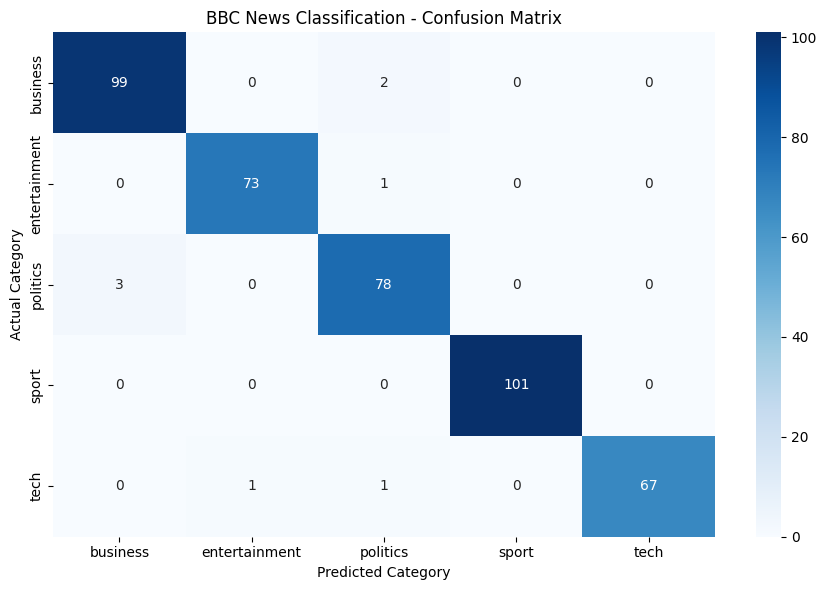

In [168]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=news_model.classes_,
    yticklabels=news_model.classes_
)

plt.title("BBC News Classification - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

### 15.3 Confusion Matrix Observations

1. Examine the diagonal values to identify correct predictions.
2. Identify categories with more incorrect predictions.
3. Observe which categories the model confuses with each other.
4. Use these observations to identify possible improvements.

The confusion matrix provides additional information
that accuracy alone cannot explain.

# 16. Model Comparison

Different machine learning algorithms can produce
different classification results on the same dataset.

We will compare three algorithms:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine

All models will use the same TF-IDF training and testing
features so that the comparison is fair.

## 16.1 Import Additional Algorithms

In [169]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

## 16.2 Initialize Models

In [170]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC()
}

## 16.3 Train and Evaluate Models

In [171]:
results = []

for model_name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    model_accuracy = accuracy_score(
        y_test,
        predictions
    )

    model_precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    model_recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    model_f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": model_accuracy,
        "Precision": model_precision,
        "Recall": model_recall,
        "F1 Score": model_f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.981221,0.981404,0.981221,0.981265
1,Logistic Regression,0.983568,0.984073,0.983568,0.983596
2,Linear SVM,0.976526,0.977039,0.976526,0.976475


## 16.4 Visualize Model Comparison

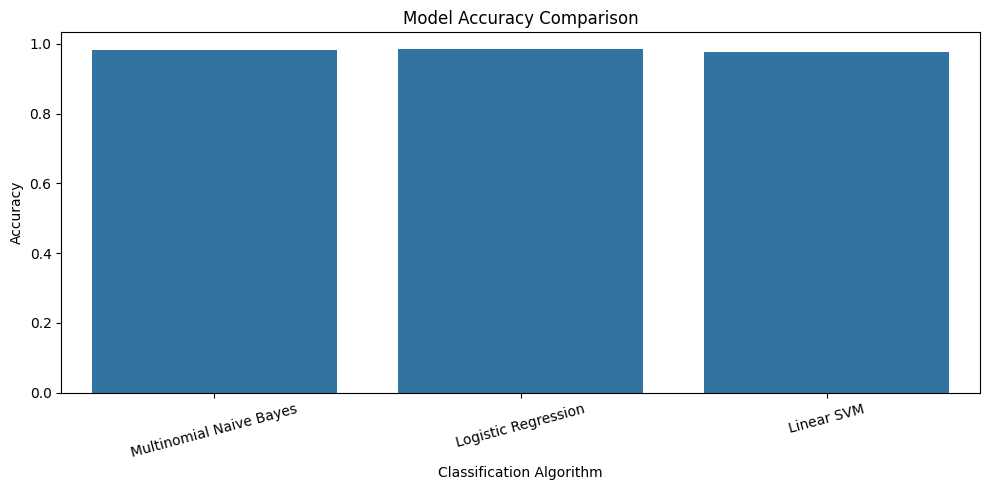

In [172]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 16.5 Select Best Model

In [173]:
best_model_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Selected Best Model:", best_model_name)

Selected Best Model: Logistic Regression


Insight: We select the model with the highest weighted F1-score, which balances precision and recall across categories. Examine accuracy as well when interpreting the results.

# 17. Prediction on New Articles

After training and evaluating the model, we can use it
to classify completely new news articles.

The prediction workflow must use the same preprocessing
steps and fitted TF-IDF vectorizer used during training.

## 17.1 Create Prediction Function

In [174]:
def predict_news_category(article):

    # Clean the new article
    cleaned_article = clean_text(article)

    # Tokenize the article
    tokens = cleaned_article.split()

    # Remove stopwords
    filtered_tokens = remove_stopwords(tokens)

    # Convert tokens back into text
    processed_article = " ".join(filtered_tokens)

    # Transform using the existing TF-IDF vectorizer
    article_vector = tfidf_vectorizer.transform(
        [processed_article]
    )

    # Predict category
    prediction = best_model.predict(article_vector)

    return prediction[0]

## 17.2 Business News Prediction

In [175]:
business_article = """
The company reported strong financial growth this year.
Its profits increased due to higher sales and improved
market performance.
"""

print(
    "Predicted Category:",
    predict_news_category(business_article)
)

Predicted Category: business


## 17.3 Entertainment News Prediction

In [176]:
entertainment_article = """
The popular actor received an award for the best
performance in a new film. The movie received positive
reviews from audiences.
"""

print(
    "Predicted Category:",
    predict_news_category(entertainment_article)
)

Predicted Category: entertainment


## 17.4 Politics News Prediction

In [177]:
politics_article = """
The government announced new policies during the
parliament session. Members discussed economic
development and public welfare.
"""

print(
    "Predicted Category:",
    predict_news_category(politics_article)
)

Predicted Category: business


## 17.5 Sports News Prediction

In [178]:
sports_article = """
The football team won the championship after an exciting
final match. The players celebrated their victory with
thousands of supporters.
"""

print(
    "Predicted Category:",
    predict_news_category(sports_article)
)

Predicted Category: sport


## 17.6 Technology News Prediction

In [179]:
technology_article = """
A technology company introduced a new smartphone with
advanced features, improved battery performance and
updated software.
"""

print(
    "Predicted Category:",
    predict_news_category(technology_article)
)

Predicted Category: tech


## 17.7 Test Your Own News Article

In [180]:
my_article = input("Enter a news article: ")

predicted_category = predict_news_category(my_article)

print("\nPredicted News Category:", predicted_category)

Enter a news article:  Software engineers have unveiled a new open-source machine learning framework designed to speed up natural language processing on standard hardware. Cybersecurity researchers also highlighted that major cloud providers are adopting stronger encryption protocols to protect user data against automated cyberattacks.



Predicted News Category: tech


# 18. Model Saving and Loading

After selecting the best-performing model, we will save
the trained classifier and TF-IDF vectorizer.

This allows us to reuse the trained model without
performing the entire training process again.

## 18.1 Import Joblib

In [181]:
import joblib

## 18.2 Save Trained Model

In [182]:
joblib.dump(
    best_model,
    "bbc_news_model.pkl"
)

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


## 18.3 Save TF-IDF Vectorizer

In [183]:
joblib.dump(
    tfidf_vectorizer,
    "bbc_tfidf_vectorizer.pkl"
)

print("TF-IDF Vectorizer Saved Successfully!")

TF-IDF Vectorizer Saved Successfully!


## 18.4 Load Saved Model

In [184]:
loaded_model = joblib.load(
    "bbc_news_model.pkl"
)

loaded_vectorizer = joblib.load(
    "bbc_tfidf_vectorizer.pkl"
)

print("Saved Model and Vectorizer Loaded Successfully!")

Saved Model and Vectorizer Loaded Successfully!


## 18.5 Test Loaded Model

In [185]:
new_article = """
The football club announced its new manager ahead
of the upcoming international tournament.
"""

cleaned_article = clean_text(new_article)

tokens = cleaned_article.split()

filtered_tokens = remove_stopwords(tokens)

processed_article = " ".join(filtered_tokens)

article_vector = loaded_vectorizer.transform(
    [processed_article]
)

prediction = loaded_model.predict(article_vector)

print("Predicted News Category:", prediction[0])

Predicted News Category: sport


In [188]:
import gradio as gr
import joblib

# Load trained model and TF-IDF vectorizer
loaded_model = joblib.load("bbc_news_model.pkl")
loaded_vectorizer = joblib.load("bbc_tfidf_vectorizer.pkl")

def predict_news(article):

    cleaned_article = clean_text(article)

    tokens = cleaned_article.split()

    filtered_tokens = remove_stopwords(tokens)

    processed_article = " ".join(filtered_tokens)

    article_vector = loaded_vectorizer.transform(
        [processed_article]
    )

    prediction = loaded_model.predict(article_vector)

    return prediction[0]

# Create Gradio interface
demo = gr.Interface(
    fn=predict_news,
    inputs=gr.Textbox(
        lines=8,
        label="Enter News Article"
    ),
    outputs=gr.Textbox(label="Predicted News Category"),
    title="BBC News Article Classification",
    description="Enter a news article to predict its category."
)

# Launch application
demo.launch()

# public url
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
* Running on public URL: https://959556f42c7597a7e5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 19. Final Project Insights

## 19.1 Workflow Summary

The complete NLP workflow included:

- Dataset collection and loading
- Data understanding
- Exploratory data analysis
- Data cleaning
- Text preprocessing
- Tokenization
- Stopword removal
- Stemming and lemmatization demonstration
- Feature and target selection
- Train-test split
- TF-IDF feature extraction
- Model building and training
- Model evaluation
- Confusion matrix analysis
- Model comparison
- Prediction on new articles
- Model saving and loading

## 19.2 Key Findings

Record your actual observations from the EDA and model
evaluation results.

Consider:

- Distribution of news categories.
- Article length patterns.
- Quality of the cleaned text.
- Most challenging categories for classification.
- Differences between the tested algorithms.

## 19.3 Model Performance

Record the actual accuracy, precision, recall, and
weighted F1-score obtained from your experiment.

Compare the performance of all three classification
algorithms.

## 19.4 Project Limitations

- Performance depends on the quality of the dataset.
- The model may struggle with articles from unfamiliar domains.
- Basic preprocessing may not capture all language variations.
- The dataset may not represent modern news terminology.

## 19.5 Future Improvements

- Experiment with stemming and lemmatization.
- Experiment with different TF-IDF settings.
- Use n-grams to capture short word combinations.
- Apply hyperparameter tuning.
- Explore advanced NLP models such as LSTM and BERT.
- Test with larger and more recent news datasets.

## 19.6 Display Final Model Performance

In [186]:
best_predictions = best_model.predict(X_test_tfidf)

final_accuracy = accuracy_score(
    y_test,
    best_predictions
)

final_precision = precision_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        round(final_accuracy, 4),
        round(final_precision, 4),
        round(final_recall, 4),
        round(final_f1, 4)
    ]
})

print("Selected Model:", best_model_name)

display(final_results)

Selected Model: Logistic Regression


,Metric,Score
0,Accuracy,0.9836
1,Precision,0.9841
2,Recall,0.9836
3,F1 Score,0.9836


# 20. Project Conclusion

In this project, we successfully developed an end-to-end
Natural Language Processing solution for BBC News
Category Classification.

The project demonstrates how unstructured news article
text can be processed, transformed into numerical
features, and used to train machine learning models.

We explored different NLP preprocessing techniques,
including text cleaning, tokenization, and stopword removal.

TF-IDF was used for feature extraction, and multiple
machine learning algorithms were evaluated for
classification performance.

The best-performing model was selected based on its
weighted F1-score.

The final model can predict the category of new,
unseen news articles and can be saved for future use.

### Final Learning Outcomes

1. Understood the complete NLP workflow.
2. Learned how to process unstructured textual data.
3. Applied different text preprocessing techniques.
4. Understood TF-IDF feature extraction.
5. Built machine learning models for text classification.
6. Evaluated models using multiple performance metrics.
7. Compared different classification algorithms.
8. Implemented predictions on new textual data.

### Final Outcome

This project demonstrates the practical application of
Natural Language Processing and Machine Learning for
automated news article categorization.